# Data Cleaning

## Importing

In [1]:
#for cleaning
import pandas as pd
import numpy as np
#for analysis
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore") #Some analysis had problems with warnings

## Common Data Set \(CDS\) Scraping

The CDS contains data about 2025\-26 applications that could not be found in the IPEDS dataset\. 2025\-26 is an important year to include as a post\-AI datapoint since AI is very easily accessible and at its most accurate during this time\. The terms and conditions of the website were read to assure that scraping of the website was allowed\. After all the 2025\-26 data on all universities present on the website was scraped, it was put into commondatasets\_admissions\.csv \.

The dataframe can be cleaned to only contain the data needed about applications received by each university, amount of applications admitted, and school information\. Before removing unwanted columns, the dataframe must be read and displayed so that we can eliminate columns unrelated to our question\.

In [2]:
df = pd.read_csv("commondatasets_admissions.csv")
[c for c in df.columns if any(k in c.lower() for k in ["appl", "admit", "name", "school"])]

['name',
 'school_type',
 'applicants_total',
 'applicants_men',
 'applicants_women',
 'admitted_total',
 'admitted_men',
 'admitted_women',
 'application_fee',
 'waitlist_admitted',
 'ea_apps_admitted',
 'applicant_pools.ea',
 'applicant_pools.rd',
 'applicant_pools.waitlist',
 'gender_breakdown.applied.male',
 'gender_breakdown.applied.female',
 'admission_factors.applicant_interest',
 'transfer_stats.male.applied',
 'transfer_stats.male.admitted',
 'transfer_stats.female.applied',
 'transfer_stats.female.admitted',
 'transfer_stats.total.applied',
 'transfer_stats.total.admitted',
 'applicant_pools',
 'applicant_pools.ea.applied',
 'applicant_pools.ea.admitted',
 'applicant_pools.ea.rate',
 'applicant_pools.rd.applied',
 'applicant_pools.rd.admitted',
 'applicant_pools.rd.rate',
 'applicant_pools.waitlist.offered',
 'applicant_pools.waitlist.accepted_spots',
 'applicant_pools.waitlist.enrolled']

Now, we only keep the necessary columns to our research question about applications sent out and accepted, and school information\. Also, the acceptance rate has to be calculated manually by dividing total admitted students for a school by applicants total\. Since all this data is from 2025\-26, the year for each datapoint is chosen to be 2025\.

In [3]:
latest_df_clean=df[["name","applicants_total","admitted_total"]].copy()
latest_df_clean["acceptance_rate"]=latest_df_clean["admitted_total"]/latest_df_clean["applicants_total"]
latest_df_clean["year"]=2025
latest_df_clean.to_csv("clean_df_2025.csv", index=False)
latest_df_clean.head(10)

,name,applicants_total,admitted_total,acceptance_rate,year
0,University of Alabama at Birmingham,11119,10474,0.941991,2025
1,American University,20960,13741,0.655582,2025
2,Amherst College,15819,1222,0.077249,2025
3,Arizona State University,69617,61533,0.883879,2025
4,Auburn University,59121,27724,0.468937,2025
5,Barnard College,10426,1048,0.100518,2025
6,Baylor University,44924,23459,0.522193,2025
7,UC Berkeley,126864,14524,0.114485,2025
8,Binghamton University,61197,22835,0.373139,2025
9,Boston University,76776,9853,0.128334,2025


## IPEDS Dataset

Open all of the datasets in the folder "admissionenroll1724", which contains all admission data available for universities present in the database from 2017 to 2024\. From IPEDS there were datasets for every single year\. These were added to a folder which was uploaded into the deepnote project\. In order to clean up the data, this code has to open all of the files\.

In [4]:
datasets = []
for year in range(2017, 2025):
    df = pd.read_csv('admissionenroll1724/adm_' + str(year) + '.csv', encoding='utf-8-sig')
    datasets.append(df)

len(datasets)

8

Begin creating a combined table that will have all of the years in one table\. All of the years are separate files on the IPEDS website\. In order to conduct the calculations and analysis, in addition to just having it more visually pleasing for reading the data, the years needed to be combined into one dataset\. This code block adds all years from 2017\-2024, downloaded from IPEDS, into one dataset\.

In [5]:
for df in datasets:
    df.columns = [col.split('.')[-1] for col in df.columns]

combined = pd.concat(datasets)

combined.shape

(47768, 12)

Drop the undesired columns\. Not all of the columns in the admissions data are useful to us\. When downloading from the IPEDS website, the admissions section contains lots of information beyond just acceptance rates and applications submitted\. So, we entered in the desired columns and had all of the columns which did not match our desired columns dropped\. This cleans up the data a lot, meaning the information is all informative for our project now and there is a lot less raw data that we have to sift through\. The files also get significantly smaller\.

In [6]:
combined = combined[['unitid', 'institution name', 'year',
                     'Applicants total', 'Admissions total', 'Enrolled total']]
combined.columns = ['unitid', 'name', 'year', 'applicants_total', 'admitted_total', 'enrolled_total']

combined = combined.dropna(subset=['applicants_total'])

combined.shape

(15258, 6)

Reorder so that it is organized by school name, not by year\. This utilizes a sorting chunk of code\. In order to be able to read the raw data easier, we believed that seeing it ordered by school rather than by year would make for more digestible code\. So, a reordering code chunk was written\.

In [7]:
combined = combined.sort_values(['name', 'unitid', 'year']).reset_index(drop=True)

combined.to_csv('ipeds_2017_2024.csv', index=False)

combined.head(10)

,unitid,name,year,applicants_total,admitted_total,enrolled_total
0,214023,ASPIRA City College,2017,3.0,3.0,2.0
1,214023,ASPIRA City College,2018,8.0,4.0,2.0
2,214023,ASPIRA City College,2021,3.0,3.0,3.0
3,214023,ASPIRA City College,2022,3.0,3.0,2.0
4,214023,ASPIRA City College,2023,3.0,3.0,3.0
5,214023,ASPIRA City College,2024,6.0,3.0,3.0
6,222178,Abilene Christian University,2017,10252.0,5952.0,972.0
7,222178,Abilene Christian University,2018,11569.0,6590.0,924.0
8,222178,Abilene Christian University,2019,11379.0,6996.0,932.0
9,222178,Abilene Christian University,2020,10534.0,6679.0,859.0


Remove entries if there were under 100 applications submitted to said college in a given year\. This is done through a simple piece of code which reads through every single year for a school\. If in any given year the amount of applications received was under 100, then all entries for that specific school are going to be removed\. We believe that in order for the data to be representative of overall trends, there needs to be a baseline number of applications, 100, that a school was consistently receiving\.

In [8]:
combined = combined[~combined['unitid'].isin(combined[combined['applicants_total'] < 100]['unitid'])].reset_index(drop=True)
combined.to_csv('ipeds_2017_2024.csv', index=False)

combined.head(10)

,unitid,name,year,applicants_total,admitted_total,enrolled_total
0,222178,Abilene Christian University,2017,10252.0,5952.0,972.0
1,222178,Abilene Christian University,2018,11569.0,6590.0,924.0
2,222178,Abilene Christian University,2019,11379.0,6996.0,932.0
3,222178,Abilene Christian University,2020,10534.0,6679.0,859.0
4,222178,Abilene Christian University,2021,8208.0,5755.0,833.0
5,222178,Abilene Christian University,2022,11226.0,7386.0,893.0
6,222178,Abilene Christian University,2023,10510.0,6714.0,862.0
7,222178,Abilene Christian University,2024,11332.0,7482.0,906.0
8,138558,Abraham Baldwin Agricultural College,2017,1927.0,1353.0,883.0
9,138558,Abraham Baldwin Agricultural College,2018,2389.0,1647.0,1017.0


Add the acceptance rate and yield rate for every school\. Acceptance rate and yield rate are important measures which can be evaluated for further analysis of the trends in college admissions during the baseline, COVID, and AI eras\. These numbers were already tracked in the original dataset\. So, they are brought back and amended onto the data once more\.

In [9]:
combined['acceptance_rate'] = (combined['admitted_total'] / combined['applicants_total'] * 100).round(1)
combined['yield_rate'] = (combined['enrolled_total'] / combined['admitted_total'] * 100).round(1)

combined.to_csv('ipeds_2017_2024.csv', index=False)

combined.head(10)

,unitid,name,year,applicants_total,admitted_total,enrolled_total,acceptance_rate,yield_rate
0,222178,Abilene Christian University,2017,10252.0,5952.0,972.0,58.1,16.3
1,222178,Abilene Christian University,2018,11569.0,6590.0,924.0,57.0,14.0
2,222178,Abilene Christian University,2019,11379.0,6996.0,932.0,61.5,13.3
3,222178,Abilene Christian University,2020,10534.0,6679.0,859.0,63.4,12.9
4,222178,Abilene Christian University,2021,8208.0,5755.0,833.0,70.1,14.5
5,222178,Abilene Christian University,2022,11226.0,7386.0,893.0,65.8,12.1
6,222178,Abilene Christian University,2023,10510.0,6714.0,862.0,63.9,12.8
7,222178,Abilene Christian University,2024,11332.0,7482.0,906.0,66.0,12.1
8,138558,Abraham Baldwin Agricultural College,2017,1927.0,1353.0,883.0,70.2,65.3
9,138558,Abraham Baldwin Agricultural College,2018,2389.0,1647.0,1017.0,68.9,61.7


## Combine datasets

Now that we have two separate datasets, we need to combine them to get a full picture of the college application system before and after the rise of AI\. We need to only include schools present in both dataframes since we want a full picture of admissions data from 2017 to 2025\. Then, we can do analysis on the finished dataset\.

In [10]:
# Schools present in both datasets
common = set(latest_df_clean["name"]) & set(combined["name"])
print(len(common), "schools appear in both")

# Keep only the shared schools in each, then stack
final = pd.concat([
    latest_df_clean[latest_df_clean["name"].isin(common)],
    combined[combined["name"].isin(common)],
], ignore_index=True)

#Organize by school name
final = final.sort_values(by="name")
final.to_csv("final_df.csv", index=False)

# Check: dataframe shape
print(final.shape)
final.head()

123 schools appear in both
(1107, 8)


,name,applicants_total,admitted_total,acceptance_rate,year,unitid,enrolled_total,yield_rate
129,American University,17786.0,8427.0,47.400000,2023,131159.0,1856.0,22.0
1,American University,20960.0,13741.0,0.655582,2025,NaN,NaN,NaN
130,American University,17173.0,10640.0,62.000000,2024,131159.0,1662.0,15.6
128,American University,19510.0,7926.0,40.600000,2022,131159.0,1761.0,22.2
127,American University,19650.0,12594.0,64.100000,2021,131159.0,2372.0,18.8


One issue presented here is that only the IPEDS dataset contained information about enrollment and individual applicant information\. Since this data could be valuable, we decided to keep the data and allow the 2025 data to be NaN for these columns\. If it provides a meaningful output, this IPEDS data will be used and have the 2025 datapoints omitted in the future\.

# Exploratory Analysis

To see what kind of relationship application and acceptance numbers have over the years, we will do different analyses\. It is important to note that for what is labeled as "2025" or "2017", this means student who were enrolled in the given year and applied late the year before or early the same year\. This means that we define the first year with AI used to be 2024, and the transition phase to be during 2023\. 

## Single Variable Analysis

### Applications

To see the spread of application numbers for different schools \(not accounting for year\), a histogram is best to visualize this\. This data can help us see if the data is skewed towards schools who receive low amounts of applications, which could affect our modeling\.

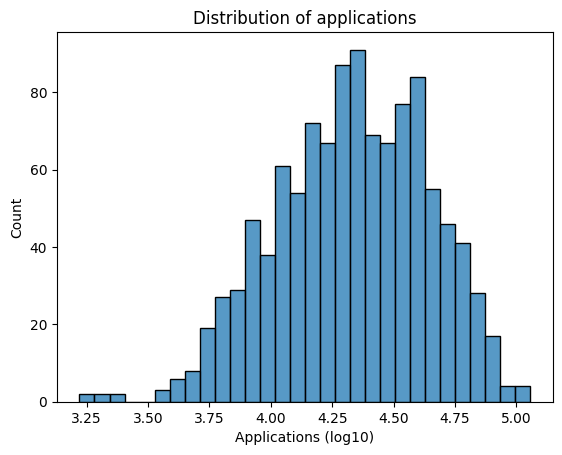

In [11]:
sns.histplot(np.log10(final["applicants_total"]), bins=30) #Application numbers vary greatly so log is needed to see the distribution
plt.xlabel("Applications (log10)")
plt.title("Distribution of applications")
plt.show()

There is no strong skew in the data when the number of applications is plotted on a log scale\. The distribution seems to be Gaussian with a center around 1e4\.25 applications\. There are a few schools with small numbers of applications, but not a large amount to make this data seem unusual to use in calculations\.

### Acceptances

The distribution of acceptances for colleges can help provide insight into if our data is usable\. There is no need to use a log scale for acceptance rates in colleges since it is already a normalized value\. The following histogram plots all data from schools regardless of year\.

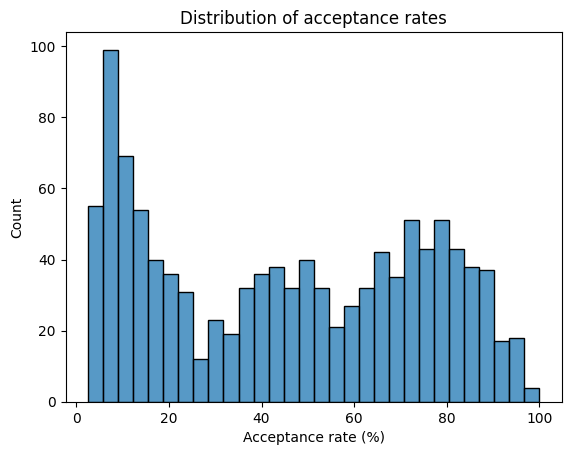

In [12]:
#Calculate acceptance rates
final["acc_rate"] = final["admitted_total"] / final["applicants_total"]
final = final.sort_values(["name", "year"])

#Plot the distribution of acceptance rates
sns.histplot(final["acc_rate"] * 100, bins=30)
plt.xlabel("Acceptance rate (%)")
plt.title("Distribution of acceptance rates")
plt.show()

The distribution is roughly uniform with a strong spike at around 5\-10% acceptance\. This most likely corresponds to Top 20 or Ivy League schools\. There seems to be no issue using this data with no strong skew or outliers\.

## 2 Variable Analysis

### Application and AI Statistics

To get a broad overview of how applications sent out have changed for all schools, we will make a graph of application number changes for all schools\. There is not much value to plotting the raw values since there is large variation in application numbers\. It is important to create an index to compare the number of applications submitted over time since large and small schools will have vastly different raw changes in admissions data \(ex\. 100 vs 10000 application number differences\) and taking 2019 as a baseline year to compare each year to since it is pre\-AI by our definition\. Then, using the index, we can plot the number of applications over time to schools\.

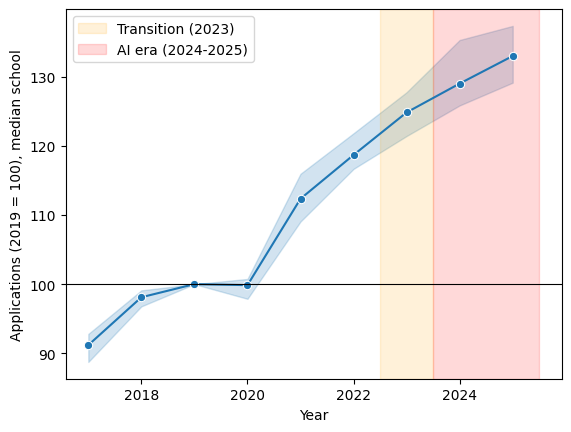

In [13]:
#Establish baseline year and calculate application index
base = final[final["year"] == 2019].set_index("name")["applicants_total"]
final["application_index"] = 100 * final["applicants_total"] / final["name"].map(base)

#Graph the data
ax = sns.lineplot(data=final, x="year", y="application_index", estimator="median", marker="o")
ax.axhline(100, color="black", linewidth=0.8)
ax.axvspan(2022.5, 2023.5, color="orange", alpha=0.15, label="Transition (2023)")
ax.axvspan(2023.5, 2025.5, color="red", alpha=0.15, label="AI era (2024-2025)")
ax.set_xlabel("Year")
ax.set_ylabel("Applications (2019 = 100), median school")
ax.legend()
plt.show()

To look more specifically at our research question, we can take the application number growth rate changes for all universities over the years and compare that\. This bar plot takes the median of a university's yearly growth rate compared to the year before and plots it per year\. 

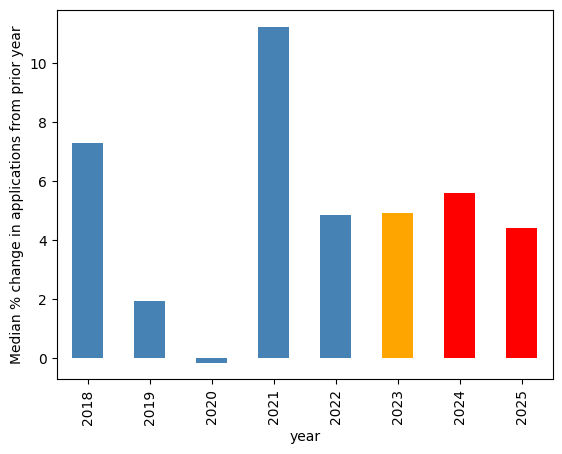

In [14]:
final = final.sort_values(["name", "year"])
final["application_growth"] = final.groupby("name")["applicants_total"].pct_change() * 100

growth = final.groupby("year")["application_growth"].median().dropna()
#colors indicated pre-ai, during, and after AI
colors = ["red" if y >= 2024 else "orange" if y == 2023 else "steelblue" for y in growth.index]
growth.plot(kind="bar", color=colors)
plt.ylabel("Median % change in applications from prior year"); plt.show()

To better see how application numbers changed per university instead of generalizing it and taking the median of all schools per year, the above graph can be made as a boxplot to better see the distribution of universities per year\.

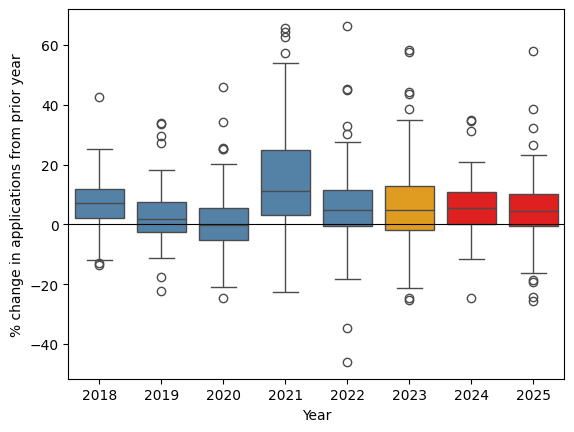

In [15]:
plot_df = final.dropna(subset=["application_growth"]).copy()
plot_df["year_str"] = plot_df["year"].astype(str)

def era_color(y):
    return "red" if y >= 2024 else "orange" if y == 2023 else "steelblue"

palette = {str(y): era_color(y) for y in plot_df["year"].unique()}

sns.boxplot(data=plot_df, x="year_str", y="application_growth",
            hue="year_str", palette=palette, legend=False)
plt.axhline(0, color="black", linewidth=0.8)
plt.xlabel("Year")
plt.ylabel("% change in applications from prior year")
plt.show()

Using the previously calculated application numbers of universities growth data, we can compile summary statistics to numerically show what is plotted in the boxplot\. 2017 cannot be compared to a previous year, so it has NaN values\. 

In [16]:
final.groupby("year")["application_growth"].describe().round(1)

,count,mean,std,min,25%,50%,75%,max
year,,,,,,,,
2017,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2018,123.0,6.9,8.2,-13.7,2.0,7.3,11.8,42.4
2019,123.0,3.2,8.4,-22.2,-2.5,1.9,7.3,33.8
2020,123.0,0.6,10.2,-24.5,-5.4,-0.1,5.4,45.8
2021,123.0,14.6,16.4,-22.5,3.3,11.2,24.8,65.6
2022,123.0,5.9,12.9,-46.0,-0.4,4.9,11.5,66.3
2023,123.0,6.4,13.5,-25.2,-2.0,4.9,12.9,58.1
2024,123.0,5.5,8.9,-24.7,0.2,5.6,10.7,35.0
2025,123.0,4.5,11.1,-25.7,-0.4,4.4,10.3,57.8


There seems to be some change across the years in application numbers to universities, but the most notable change happened in 2021 with the start of test optional policies\. Looking at post\-AI data, the application numbers do seem to be growing but more statistics will have to be done in order to see if it is significant change\. One possible change to our research question may be to stratify the data by Top 20 schools or public/private universities to see if there is a more pronounced difference there\.

### Acceptance and AI Statistics

Now, to get a basic overview of acceptance rates and how they have changed, we will graph the acceptance rates in the same fashion as above\. There will be a lineplot to show the indexed acceptance rates over time\. Then, we will find the median acceptance rates for all universities for each year, then graph the changes as boxplots and barplots\. 

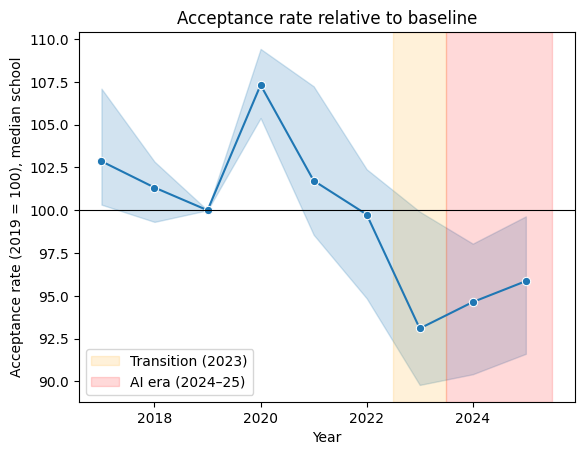

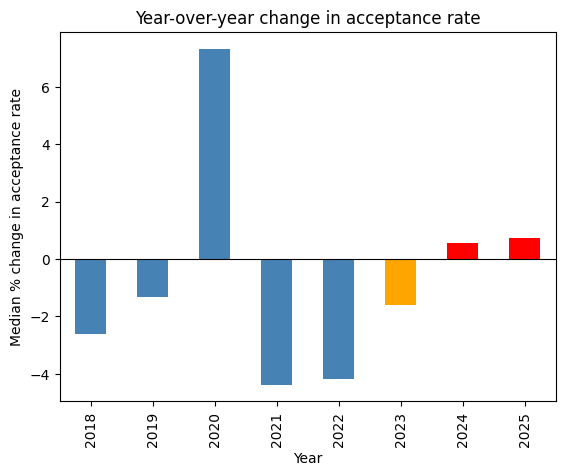

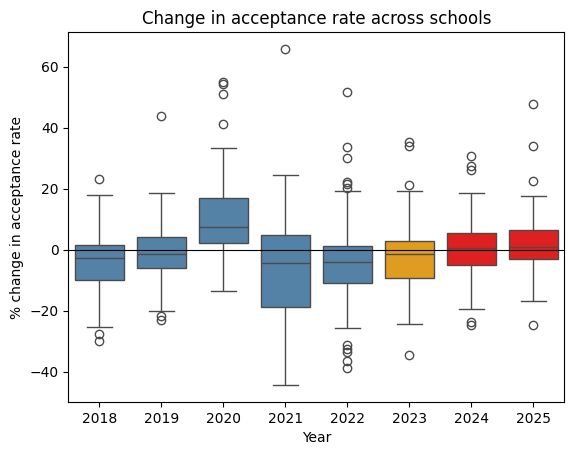

,count,mean,std,min,25%,50%,75%,max
year,,,,,,,,
2017,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2018,123.0,-4.1,9.2,-29.8,-9.9,-2.6,1.5,23.0
2019,123.0,-0.9,9.2,-23.0,-6.0,-1.3,4.1,43.8
2020,123.0,10.1,12.6,-13.5,2.2,7.3,17.1,54.9
2021,123.0,-6.6,16.9,-44.4,-18.8,-4.4,4.8,65.8
2022,123.0,-4.3,13.2,-38.7,-11.0,-4.2,1.1,51.6
2023,123.0,-2.0,10.9,-34.7,-9.2,-1.6,2.8,35.3
2024,123.0,0.3,9.4,-24.8,-5.0,0.6,5.3,30.8
2025,123.0,1.8,9.2,-24.8,-3.2,0.7,6.6,47.6


In [17]:
BASE_YEAR = 2019  #Pre-AI baseline

#Define color coding for pre/post AI eras
def era_color(y):
    return "red" if y >= 2024 else "orange" if y == 2023 else "steelblue"

# 1. Indexed acceptance rate (each school's BASE_YEAR = 100, which is 2019) 
base = final[final["year"] == BASE_YEAR].set_index("name")["acc_rate"]
final["acc_index"] = 100 * final["acc_rate"] / final["name"].map(base)

ax = sns.lineplot(data=final, x="year", y="acc_index", estimator="median", marker="o")
ax.axhline(100, color="black", linewidth=0.8)
ax.axvspan(2022.5, 2023.5, color="orange", alpha=0.15, label="Transition (2023)")
ax.axvspan(2023.5, 2025.5, color="red", alpha=0.15, label="AI era (2024–25)")
ax.set_xlabel("Year")
ax.set_ylabel(f"Acceptance rate (2019 = 100), median school")
ax.set_title("Acceptance rate relative to baseline")
ax.legend()
plt.show()

# 2. Bar chart: median % change in acceptance rate from prior year 
final["acc_growth"] = final.groupby("name")["acc_rate"].pct_change() * 100

acc_growth = final.groupby("year")["acc_growth"].median().dropna()
acc_growth.plot(kind="bar", color=[era_color(y) for y in acc_growth.index])
plt.axhline(0, color="black", linewidth=0.8)
plt.ylabel("Median % change in acceptance rate")
plt.xlabel("Year")
plt.title("Year-over-year change in acceptance rate")
plt.show()

# 3. Box plot: spread of % change across schools 
plot_df = final.dropna(subset=["acc_growth"]).copy()
plot_df["year_str"] = plot_df["year"].astype(str)
palette = {str(y): era_color(y) for y in plot_df["year"].unique()}

sns.boxplot(data=plot_df, x="year_str", y="acc_growth",
            hue="year_str", palette=palette, legend=False)
plt.axhline(0, color="black", linewidth=0.8)
plt.ylabel("% change in acceptance rate")
plt.xlabel("Year")
plt.title("Change in acceptance rate across schools")
plt.show()

# 4. Summary statistics
final.groupby("year")["acc_growth"].describe().round(1)

As with the application number statistics, it is hard to see a statistically significant change between pre vs post\-AI with 2019 as a reference\. A potential change to our research question could be to group the data by private/public schools or state/Top 20 schools\. There may also be a way to stratify the data by gender of applicant or cost of application to see if there is a statistically significant difference in acceptances across schools\. 

# Sources 

Claude was used to help with the data cleaning and exploratory analysis\.

For the graphs, this website was helpful in highlight certain parts of the graph\. https://stackoverflow\.com/questions/8270981/how\-to\-highlight\-specific\-x\-value\-ranges

<a style='text-decoration:none;line-height:16px;display:flex;color:#5B5B62;padding:10px;justify-content:end;' href='https://deepnote.com?utm_source=created-in-deepnote-cell&projectId=5504e1cb-e852-40a9-a959-1b5368c81868' target="_blank">

Created in <span style='font-weight:600;margin-left:4px;'>Deepnote</span></a>